In [1]:
from data_process import *
from mcar.estimate import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

# Initialization
# Tickers
TICKERS = ['SPY', 'AMZN', 'JPM', 'GS', 'KO', 'MSFT', 'NDAQ', 'MNST']

# Number of covariate
C = 1

# Aggregation interval for realized correlation/covariance (1 hour)
rule = 'h'

# Sample interval (1 second)
sample_interval = '1s'

# Forecast steps
forecast_step = 1

# Set hyperparameter gamma
gamma = 1.01

In [ ]:
'''
# Data Processing
# Training set
for TICKER in TICKERS:
    input_path = './data/LOBSTERdata/_' + TICKER + '_2023-01-01_2025-06-30'
    log_path = './data/LOBSTERdata/log/train/' + TICKER + '_processing_logs'
    os.makedirs(log_path, exist_ok=True)
    output_path = './data/LOBSTERdata/output/train/' + TICKER
    os.makedirs(output_path, exist_ok=True)
    multiprocess_orderbooks(TICKER=TICKER, input_path=input_path, output_path=output_path, log_path=log_path, check_for_processed_data=True, sample_interval=sample_interval)

aggregate_assets(TICKERS, './data/LOBSTERdata/output/train/', './data/LOBSTERdata/output/train/aggregate/')

# Testing set
for TICKER in TICKERS:
    input_path = './data/LOBSTERdata/_' + TICKER + '_2025-07-01_2026-02-01'
    log_path = './data/LOBSTERdata/log/test/' + TICKER + '_processing_logs'
    os.makedirs(log_path, exist_ok=True)
    output_path = './data/LOBSTERdata/output/test/' + TICKER
    os.makedirs(output_path, exist_ok=True)
    multiprocess_orderbooks(TICKER=TICKER, input_path=input_path, output_path=output_path, log_path=log_path, check_for_processed_data=True, sample_interval=sample_interval)
    
aggregate_assets(TICKERS, './data/LOBSTERdata/output/test/', './data/LOBSTERdata/output/test/aggregate/')

# Compute and save correlation/covariance data
log_data_to_corr_data('./data/LOBSTERdata/output/train/aggregate/', rule, delta=.6, theta=1)
log_data_to_corr_data('./data/LOBSTERdata/output/test/aggregate/', rule, delta=.6, theta=1)
log_data_to_corr_data('./data/LOBSTERdata/output/train/aggregate/', rule, delta=.6, theta=1, is_corr=False)
log_data_to_corr_data('./data/LOBSTERdata/output/test/aggregate/', rule, delta=.6, theta=1, is_corr=False)
'''

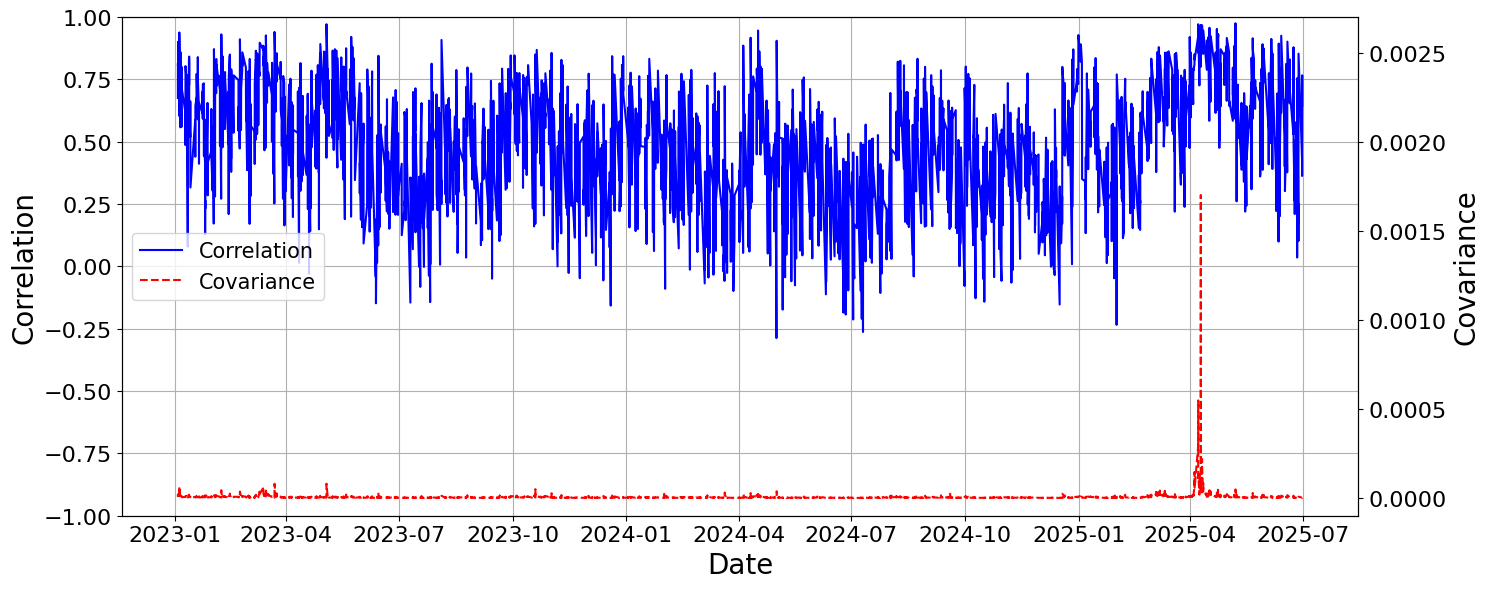

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


In [2]:
# Plot correlation/covariance for one pair
data_corr = np.load('./data/LOBSTERdata/output/train/aggregate/corr.npz', allow_pickle=True)
index = pd.to_datetime(data_corr['timestamps'])
df_corr = pd.DataFrame({key: data_corr[key] for key in data_corr.files if key != 'timestamps'}, index=index)

data_cov = np.load('./data/LOBSTERdata/output/train/aggregate/cov.npz', allow_pickle=True)
index = pd.to_datetime(data_cov['timestamps'])
df_cov = pd.DataFrame({key: data_cov[key] for key in data_cov.files if key != 'timestamps'}, index=index)

df = pd.DataFrame({
    "Correlation": df_corr['SPY_NDAQ'],
    "Covariance": df_cov['SPY_NDAQ']
}).dropna()

# --- Plot ---
fig, ax1 = plt.subplots(figsize=(15, 6))

# Correlation (left axis)
ax1.plot(df.index, df["Correlation"], label="Correlation", linestyle='-', color='blue')
ax1.set_xlabel("Date", fontsize=20)
ax1.set_ylabel("Correlation", fontsize=20)
ax1.set_ylim(-1,1)
ax1.grid(True)
ax1.tick_params(axis='both', labelsize=16)

# Covariance (right axis)
ax2 = ax1.twinx()
ax2.set_ylim(-0.0001,0.0027)
ax2.plot(df.index, df["Covariance"], label="Covariance", linestyle='--', color='red')
ax2.set_ylabel("Covariance", fontsize=20)
ax2.tick_params(axis='both', labelsize=16)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left", fontsize=15)

plt.tight_layout()
plt.show()
fig.savefig('./data/LOBSTERdata/output/train/aggregate/corr_cov.eps', format='eps')

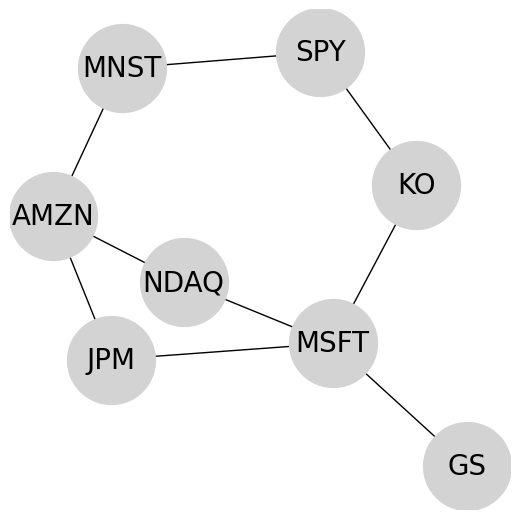

In [2]:
# Load the correlation/covariance data
data = np.load('./data/LOBSTERdata/output/train/aggregate/cov.npz', allow_pickle=True)
index = pd.to_datetime(data['timestamps'])
_data = pd.DataFrame({key: data[key] for key in data.files if key != 'timestamps'}, index=index)

# Derive network structure
#TICKERS = ['SPY', 'AMZN', 'JPM', 'GS', 'KO', 'MSFT', 'NDAQ', 'MNST']
'''
A = [[0, 1, 1, 1, 1, 1, 1, 1],
       [1, 0, 1, 1, 1, 0, 1, 1],
       [1, 1, 0, 0, 1, 0, 0, 1],
       [1, 1, 0, 0, 1, 1, 1, 0],
       [1, 1, 1, 1, 0, 0, 1, 0],
       [1, 0, 0, 1, 0, 0, 1, 1],
       [1, 1, 0, 1, 1, 1, 0, 1],
       [1, 1, 1, 0, 0, 1, 1, 0]]
'''
A = [[0., 0., 0., 0., 1., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 1., 1.],
       [0., 1., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 1., 1., 1., 0., 1., 0.],
       [0., 1., 0., 0., 0., 1., 0., 0.],
       [1., 1., 0., 0., 0., 0., 0., 0.]]

# create graph from adjacency matrix
G = nx.from_numpy_array(np.array(A))
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))

# layout for nodes
pos = nx.spring_layout(G, seed=1)

# draw graph
plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_size=4000, node_color='lightgrey', font_size=20)
plt.savefig('./data/LOBSTERdata/output/train/aggregate/network.eps', format='eps')
plt.show()

Adj = adj_to_line_graph(A, TICKERS)

# Number of edges
K = Adj[0].shape[0]

# Training data
Y = _data[Adj[1]].T

# Set time grids
P_ = np.array([0.01 * i for i in range(Y.shape[1])])
delta = 18
Q_ = np.append(P_[::delta], P_[-1]) if (Y.shape[1] - 1) % delta != 0 else P_[::delta]

# Testing data
test_data = np.load('./data/LOBSTERdata/output/test/aggregate/cov.npz', allow_pickle=True)
test_index = pd.to_datetime(test_data['timestamps'])
test_data_ = pd.DataFrame({key: test_data[key] for key in test_data.files if key != 'timestamps'}, index=test_index)
test_Y = test_data_[Adj[1]].T
test_set = sliding_window_view(test_Y, (K, forecast_step))[0]
test_size = test_set.shape[0]

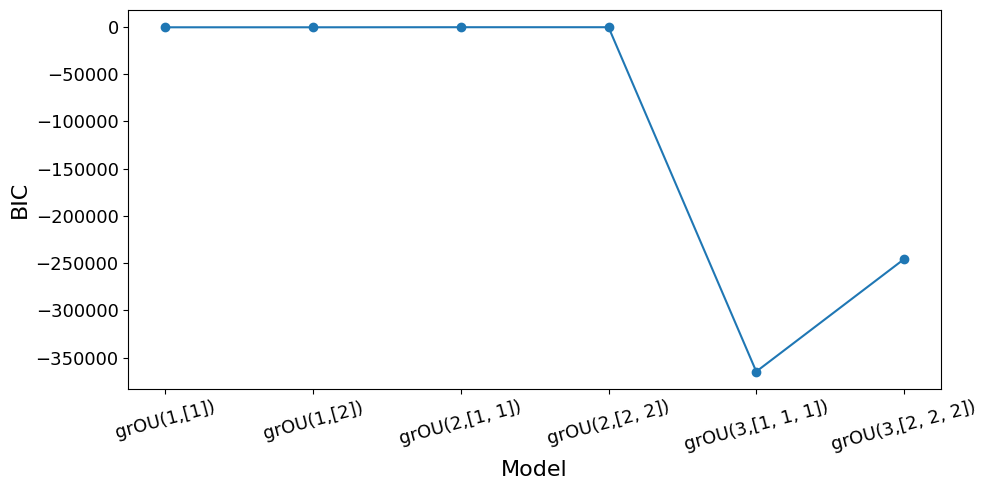

In [3]:
models = [[value] * length for length in range(1, 4) for value in (1, 2)]
bic = [grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, model, C, P_, Q_, gamma, is_global=False, print_param=True, is_test=True)[2] for model in models]

plt.figure(figsize=(10, 5))
plt.plot(['grOU(' + str(len(model)) + ',' + str(model) + ')' for model in models], bic, marker="o")
plt.xlabel("Model", fontsize=16)
plt.ylabel("BIC", fontsize=16)
plt.xticks(rotation=15)
plt.tick_params(axis='both', labelsize=13)
plt.tight_layout()
plt.savefig('./data/LOBSTERdata/output/train/aggregate/bic.eps', format='eps')
plt.show()

In [4]:
bic

[np.float64(-4752.3563057659185),
 np.float64(-4823.067799733002),
 np.float64(-4200.01336443266),
 np.float64(-4348.603472218298),
 np.float64(-3374.691154243391),
 np.float64(-3419.5798452019385)]

In [5]:
result = joint_graph_model_selection(_data, test_data_, TICKERS, [1], P_, Q_, forecast_step, C, gamma, n_candidates=1000, top_k=50, max_order=3, tol=1e-3, p=0.4)
with open("./data/LOBSTERdata/output/train/aggregate/model_selection.txt", "w") as file:
    file.write(result)

=== Step 1-4: Network screening ===
Retained 50 networks after screening.

=== Step 5: Model selection within each retained network ===

--- Retained network 1/50 ---
Screening performance: abs_diff=0.1059997566021662, bic=-514.5499906914514

--- Retained network 2/50 ---
Screening performance: abs_diff=0.10466106851649026, bic=-700.3267425108916

--- Retained network 3/50 ---
Screening performance: abs_diff=0.1035049288061336, bic=-606.9797461318292

--- Retained network 4/50 ---
Screening performance: abs_diff=0.10262869660460028, bic=-534.4046904403589

--- Retained network 5/50 ---
Screening performance: abs_diff=0.10085797736400148, bic=-931.6872889683257

--- Retained network 6/50 ---
Screening performance: abs_diff=0.10076670317634173, bic=-414.89019737789613

--- Retained network 7/50 ---
Screening performance: abs_diff=0.09967141292442505, bic=-611.4548055188883

--- Retained network 8/50 ---
Screening performance: abs_diff=0.09956188389923326, bic=-423.7463727851691

--- Reta

{'screening_RL': [1],
 'top_networks': [(np.float64(0.1059997566021662),
   array([[0., 0., 0., 0., 1., 0., 0., 1.],
          [0., 0., 1., 0., 0., 0., 1., 1.],
          [0., 1., 0., 0., 0., 1., 0., 0.],
          [0., 0., 0., 0., 0., 1., 0., 0.],
          [1., 0., 0., 0., 0., 1., 0., 0.],
          [0., 0., 1., 1., 1., 0., 1., 0.],
          [0., 1., 0., 0., 0., 1., 0., 0.],
          [1., 1., 0., 0., 0., 0., 0., 0.]]),
   np.float64(-514.5499906914514)),
  (np.float64(0.10466106851649026),
   array([[0., 1., 0., 0., 0., 0., 0., 1.],
          [1., 0., 0., 1., 0., 1., 0., 1.],
          [0., 0., 0., 0., 0., 1., 0., 0.],
          [0., 1., 0., 0., 0., 1., 0., 0.],
          [0., 0., 0., 0., 0., 1., 0., 0.],
          [0., 1., 1., 1., 1., 0., 0., 1.],
          [0., 0., 0., 0., 0., 0., 0., 0.],
          [1., 1., 0., 0., 0., 1., 0., 0.]]),
   np.float64(-700.3267425108916)),
  (np.float64(0.1035049288061336),
   array([[0., 1., 0., 0., 1., 0., 0., 1.],
          [1., 0., 0., 0., 1., 0

In [3]:
# Naive model
forecast_NA, NA_RMSE_mean = NA_model(Y, test_set, forecast_step)
print(f'The overall RMSE is: {NA_RMSE_mean}.')

The overall RMSE is: 7.1769111742733595e-06.


In [4]:
# Univariate AR Edge Model
start = time.perf_counter()
forecast_AR = UAR_model(Y, test_set, test_size, forecast_step, 1)
AR_RMSE_mean, AR_dir_mean = evaluate_forecast(Y, forecast_AR, test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {AR_RMSE_mean}. The average directional accuracy is: {AR_dir_mean}.')

The time cost is: 0.20588320001843385. The overall RMSE is: 6.270954909434179e-06. The average directional accuracy is: 0.5811123281002799.


In [5]:
# VAR Edge Model
start = time.perf_counter()
forecast_VAR = VAR_model(Y, test_set, test_size, forecast_step, 1)
VAR_RMSE_mean, VAR_dir_mean = evaluate_forecast(Y, forecast_VAR, test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {VAR_RMSE_mean}. The average directional accuracy is: {VAR_dir_mean}.')

The time cost is: 1.649655300017912. The overall RMSE is: 1.084628228819364e-05. The average directional accuracy is: 0.5422903736156748.


In [6]:
# GNAR Edge Model
start = time.perf_counter()
forecast_GNAR = GNAR_model(Y, Adj, [1], test_set, test_size, forecast_step)
GNAR_RMSE_mean, GNAR_dir_mean = evaluate_forecast(Y, forecast_GNAR, test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {GNAR_RMSE_mean}. The average directional accuracy is: {GNAR_dir_mean}.')

The time cost is: 1.0387774000118952. The overall RMSE is: 6.191777120018205e-06. The average directional accuracy is: 0.686503590118048.


In [7]:
# OU Edge model
start = time.perf_counter()
forecast_OU = OU_edge_model(Y, test_set, test_size, forecast_step, [1], C, P_, Q_, gamma, is_global=False)
OU_RMSE_mean, OU_dir_mean = evaluate_forecast(Y, forecast_OU, test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {OU_RMSE_mean}. The average directional accuracy is: {OU_dir_mean}.')

The time cost is: 2.1413273999933153. The overall RMSE is: 7.116839024698965e-06. The average directional accuracy is: 0.6863818912011683.


In [8]:
# MCAR Edge Model
start = time.perf_counter()
forecast_MCAR = MCAR_edge_model(Y, test_set, test_size, forecast_step, P_, Q_, [1], C, gamma)
MCAR_RMSE_mean, MCAR_dir_mean = evaluate_forecast(Y, forecast_MCAR , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {MCAR_RMSE_mean}. The average directional accuracy is: {MCAR_dir_mean}.')

The time cost is: 2.7458177999942563. The overall RMSE is: 7.092344089373419e-06. The average directional accuracy is: 0.5968114883777534.


In [9]:
# Graph OU Edge Model (1, [1])
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [1], C, P_, Q_, gamma, is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 2.096294399991166. The overall RMSE is: 7.117659905752213e-06. The average directional accuracy is: 0.6871120847024461.


In [10]:
# Graph OU Edge Model (1, [2])
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [2], C, P_, Q_, gamma, is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 2.0804740999883506. The overall RMSE is: 7.119736311819636e-06. The average directional accuracy is: 0.687842278203724.


In [11]:
# Graph OU Edge Model (2, [1,1])(Zero initialization)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [1,1], C, P_, Q_, gamma, method = 'naive', is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 2.498765500000445. The overall RMSE is: 7.178094325443691e-06. The average directional accuracy is: 0.5061457953024218.


In [3]:
# Graph OU Edge Model (2, [1,1])(Backward-difference)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [1,1], C, P_, Q_, gamma, method = 'backward', is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 2.847279299981892. The overall RMSE is: 1.1943327148093448e-05. The average directional accuracy is: 0.37872702932943897.


In [ ]:
def kalman_filter_mcar_BM(Y, Q_QQ, Sigma, P_, Q_, QQ_hat, gamma):
    """
    Y: (d, N+1) observations at time grid
    Q_QQ: (pd, pd) MCAR matrix
    Sigma: (d, d) Brownian covariance of Levy process
    P_: (N+1, ) observation times
    Q_: (M+1, ) coarser grid
    QQ_hat: estimated MCAR parameters, list of p (d, d) np.ndarray
    gamma: hyperparameter for defining the critical region
    Returns the last value of m_filtered, (pd, ) np.ndarray
    """
    d = Y.shape[0]
    pd = Q_QQ.shape[0]
    p = int(pd / d)

    DeltaL_Q = recover_BDLP(Y, p, P_, Q_, QQ_hat)
    DeltaW, DeltaQ_W = disentangle_BM(DeltaL_Q, Q_, Sigma, gamma)
    Q_index = np.searchsorted(Q_, np.cumsum(DeltaQ_W), side="left")
    Y_Q = Y[:, Q_index]

    # Build Sigma_tilde = E Sigma E^T, with E[-d:,:] = I_d
    E = np.zeros((pd, d))
    E[-d:, :] = np.eye(d)
    Sigma_tilde = E @ Sigma @ E.T

    M = np.zeros((2 * pd, 2 * pd))
    M[:pd, :pd] = Q_QQ
    M[:pd, pd:] = Sigma_tilde
    M[pd:, pd:] = -Q_QQ.T
    H = np.zeros((d, pd))
    H[:, :d] = np.eye(d)

    # Initial prior
    m = np.zeros(pd)
    P = np.eye(pd)
    m_filtered = [m.copy()]

    for k in range(len(DeltaQ_W)):
        expM = scipy.linalg.expm(M * DeltaQ_W[k])
        F_k = scipy.linalg.expm(Q_QQ * DeltaQ_W[k])
        Q_k = expM[:pd, pd:] @ F_k.T

        # 1) Prediction
        m_pred = F_k @ m
        P_pred = F_k @ P @ F_k.T + Q_k

        # 2) Update
        v = Y_Q[:, k] - H @ m_pred
        S = H @ P_pred @ H.T
        K = np.linalg.solve(S, H @ P_pred).T

        m = m_pred + K @ v
        P = P_pred - K @ S @ K.T

        m_filtered.append(m.copy())

    return m_filtered[-1]


In [ ]:
if len(R_L) == 1:
    x0 = window_data[:, -1]
else:
    if method == 'backward':
        # Backward - differences
        flip_window = state_space(np.flip(window_data[:, -len(R_L):], axis=1), len(R_L), P_[-len(R_L):])
        x0 = flip_window[:, 0] * np.repeat((-1) ** np.arange(len(R_L)), flip_window.shape[0] / len(R_L))
    elif method == 'naive':
        # Naive initialization
        x0 =np.append(window_data[:, -1], [0] * K * (len(R_L) - 1))
    elif method == 'kalman':
        # Kalman - filter
        x0 = kalman_filter_mcar_BM(window_data, Q_Q, Sigma_MCAR, P_, Q_, QQ_hat, gamma)
        x0[:K] = window_data[:, -1]
    else:
        raise NotImplementedError("method must be among 'backward', 'naive' or 'kalman'.")

In [3]:
# Graph OU Edge Model (2, [1,1])(Kalman filter)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [1,1], C, P_, Q_, gamma, method = 'kalman',is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

[[ -210482.26786573  -201642.36418089  -523456.81403781  -412208.52942147
   -304618.89513526  -389305.18504512  -386219.93428139  -247924.56217864
   -323453.52633001]
 [  -85904.81918822   -82296.9602679   -213640.14849671  -168236.02076724
   -124325.11001165  -158888.40361446  -157629.21008859  -101186.26572316
   -132012.14989235]
 [ -603494.08643382  -578148.34281113 -1500853.70600824 -1181882.97953026
   -873402.32359811 -1116214.58365615 -1107368.56251644  -710848.51314861
   -927404.9180278 ]
 [ -913744.33474351  -875368.59889837 -2272427.52161456 -1789477.14841278
  -1322409.68566163 -1690049.28979656 -1676655.61803882 -1076288.59395895
  -1404174.47148275]
 [ -297728.50712767  -285224.40711997  -740432.99404536  -583071.58761817
   -430885.36536177  -550674.66127114  -546310.55443538  -350690.87066666
   -457527.0710255 ]
 [ -425688.46887205  -407810.26420078 -1058661.76732066  -833668.41076304
   -616074.4673387   -787347.69359061  -781107.94861344  -501413.38906954
   -654

TypeError: 'NoneType' object does not support item assignment

In [16]:
# Graph OU Edge Model (2, [2,2])(Zero initialization)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [2,2], C, P_, Q_, gamma, method = 'naive', is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 12.97173560000374. The overall RMSE is: 7.28395877105948e-06. The average directional accuracy is: 0.4986178480154384.


In [17]:
# Graph OU Edge Model (3, [1,1,1])(Zero initialization)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [1,1,1], C, P_, Q_, gamma, method = 'naive', is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 19.947975899995072. The overall RMSE is: 7.280452359153579e-06. The average directional accuracy is: 0.5186460126219162.


In [18]:
# Graph OU Edge Model (3, [2,2,2])(Zero initialization)
start = time.perf_counter()
forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, [2,2,2], C, P_, Q_, gamma, method = 'naive', is_global=False)
grOU_RMSE_mean, grOU_dir_mean = evaluate_forecast(Y, forecast_grOU , test_set)
print(f'The time cost is: {time.perf_counter() - start}. The overall RMSE is: {grOU_RMSE_mean}. The average directional accuracy is: {grOU_dir_mean}.')

The time cost is: 15.908800000004703. The overall RMSE is: 7.280357949089937e-06. The average directional accuracy is: 0.5234444270588849.


In [20]:
# Simulation study
# Setup parameters for simulated data
adj_sim = adj_to_line_graph([[0,1,0],[1,0,1],[0,1,0]], ['a','b','c'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1,1], 2, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim')
X_sim.alpha_set(np.array([[4,3],[2,1]]))
X_sim.beta_set([[1],[1]])
X_sim.Q_matrix()

array([[ 0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  1.],
       [-2., -1., -4., -1.],
       [-1., -1., -1., -3.]])

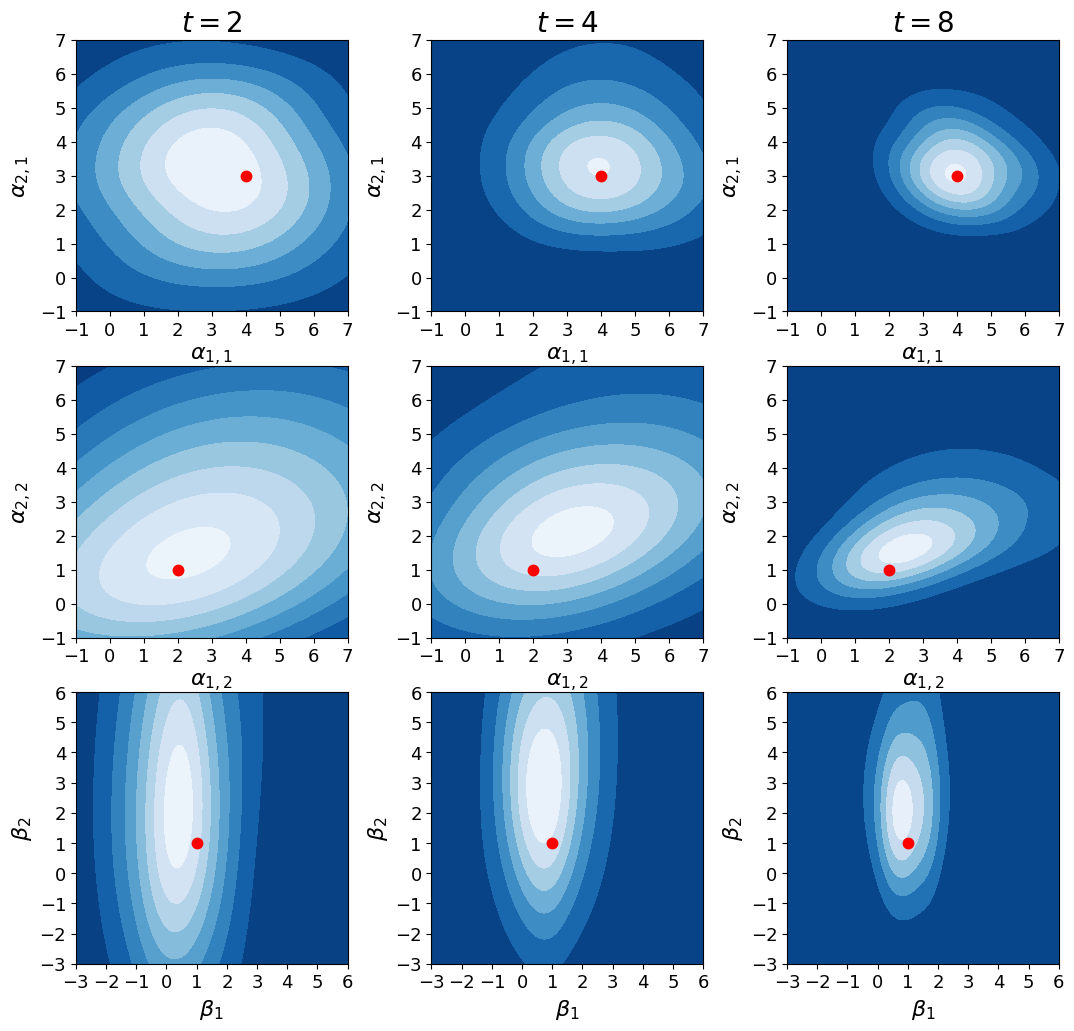

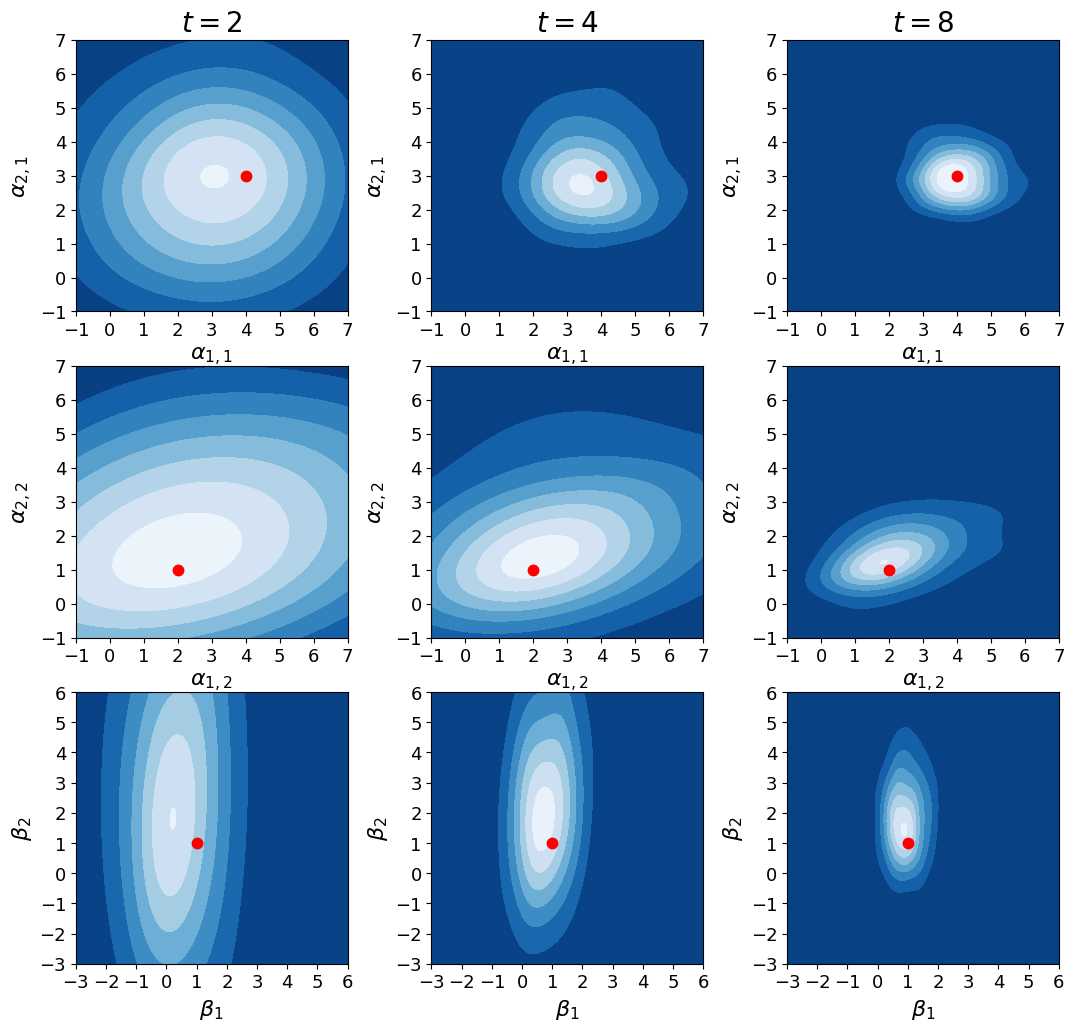

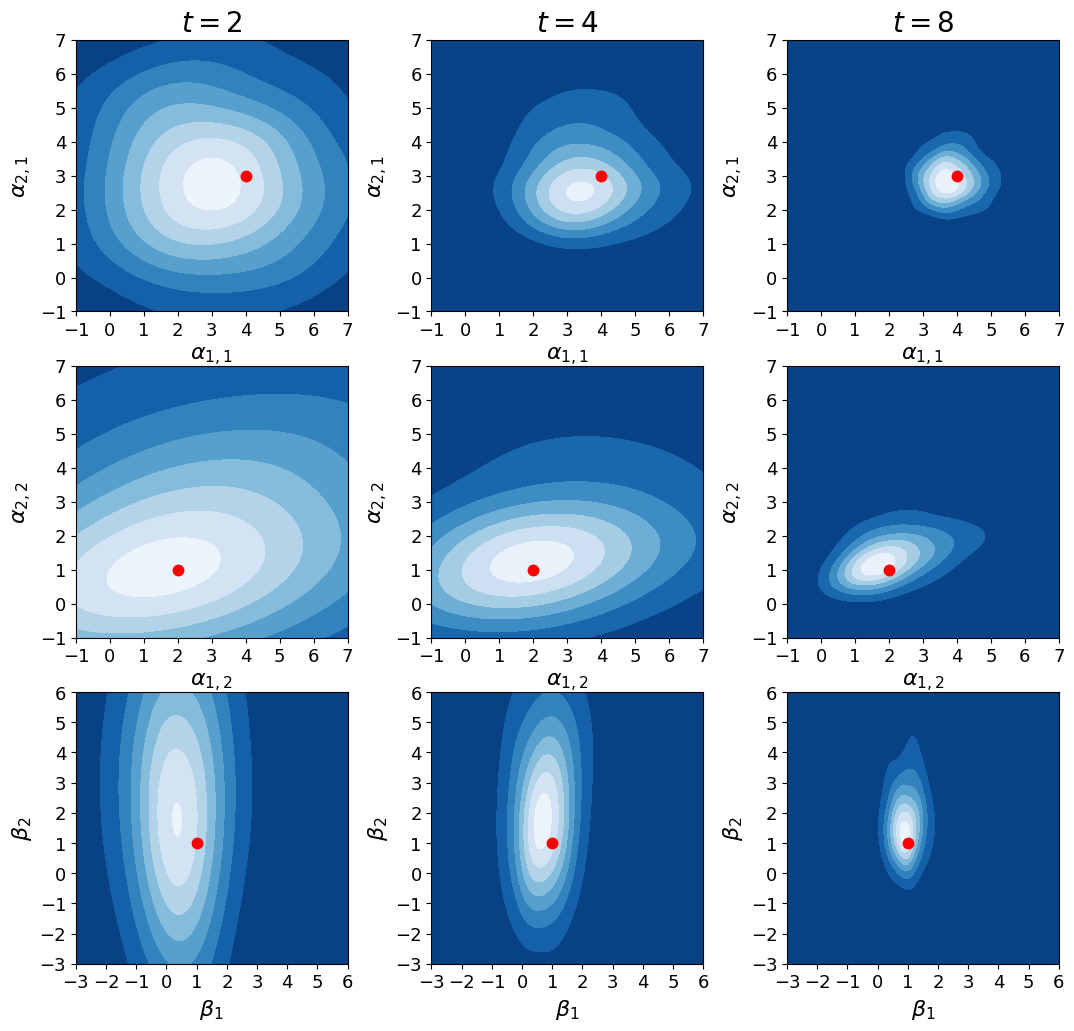

In [20]:
'''
for regime in ['BM', 'CP', 'Gamma']:
    estimate = []
    for j in range(25):
        sim = X_sim.simulate(regime, 40, seed=134 + 100 * j, rate=1)
        P = np.linspace(0, 8, 8 ** 7 + 1)
        args = [(P, [1,1], 2, 1, sim[i], adj_L_sim, W_C_sim, gamma) for i in range(40)]
        with Pool(os.cpu_count()) as pool:
            results = pool.map(process_one_sim, args)
        estimate.extend(results)

    with open('./data/LOBSTERdata/output/sim/estimate_' + regime + '.npy', 'wb') as f:
        np.save(f, estimate)
'''

for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/estimate_' + regime + '.npy', 'rb') as f:
        estimate = np.load(f)

    fig, axes = plt.subplots(3, 3, figsize=(13, 12), squeeze=False)
    for log2t in range(1, 4):
        for n in range(2):
            for m in range(1):
                ax = axes[n, log2t - 1]
                x = estimate[:, log2t - 1, n * 3 + m]
                y = estimate[:, log2t - 1, n * 3 + m + 1]
                mask = (abs(x) < 100) & (abs(y) < 100)
                x_clean = x[mask]
                y_clean = y[mask]

                k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
                xi, yi = np.mgrid[-1:7:100 * 1j, -1:7:100 * 1j]
                zi = k(np.vstack([xi.flatten(), yi.flatten()]))

                ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

                ax.set_xticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.set_yticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.tick_params(axis='both', labelsize=13)
                ax.set_xlabel(r'$\alpha_{%i,%i}$' % (2 * m + 1, n + 1), fontsize=16)
                ax.set_ylabel(r'$\alpha_{%i,%i}$' % (2 * m + 2, n + 1), fontsize=16)
                ax.plot(X_sim.Q_get()[n][2 * m][2 * m], X_sim.Q_get()[n][2 * m + 1][2 * m + 1], color='red', marker='.', markersize=15)
                ax.set_box_aspect(1)

                if n == 0 and m == 0:
                    ax.set_title(r'$t = %i$' % 2 ** log2t, fontsize=20)

        ax = axes[2, log2t - 1]
        x = estimate[:, log2t - 1, 2]
        y = estimate[:, log2t - 1, 5]
        mask = (abs(x) < 100) & (abs(y) < 100)
        x_clean = x[mask]
        y_clean = y[mask]

        k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
        xi, yi = np.mgrid[-3:6:100 * 1j, -3:6:100 * 1j]
        zi = k(np.vstack([xi.flatten(), yi.flatten()]))

        ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

        ax.set_xticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.set_yticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.tick_params(axis='both', labelsize=13)
        ax.set_xlabel(r'$\beta_{%i}$' % 1, fontsize=16)
        ax.set_ylabel(r'$\beta_{%i}$' % 2, fontsize=16)
        ax.plot(1, 1, color='red', marker='.', markersize=15)
        ax.set_box_aspect(1)

    fig.savefig('./data/LOBSTERdata/output/sim/estimate_' + regime + '.eps', bbox_inches='tight', format='eps')

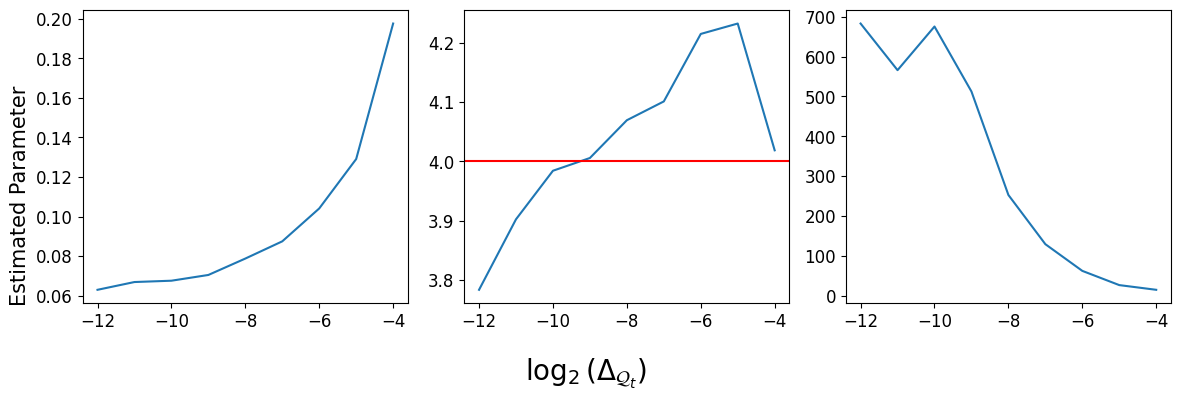

In [21]:
sim = X_sim.simulate('CP', 1, seed=3, rate=1)
P = np.linspace(0, 8, 8 ** 7 + 1)
subset_P = slice(0, int(8 ** 7 / 2) + 1, 2 ** 6)
P = P[subset_P]
alphas_grOU = []

# Underfitting
for j in range(9):
    Q = np.append(P[::2 ** j], P[-1]) if (sim.shape[2] - 1) % 2 ** j != 0 else P[::2 ** j]
    _, (b_grOU, Sigma_grOU) = estimate_MCAR('grOU', sim[0][:,subset_P], P, Q, adj_L_sim, W_C_sim, [1], 1, gamma)
    theta_hat_grOU, _, _ = estimate_grOU_drift(sim[0][:,subset_P], adj_L_sim, W_C_sim, [1], 1, P, Q, b_grOU, gamma, None, Sigma_grOU, with_cov=True, is_global=False)
    alphas_grOU.append(theta_hat_grOU.reshape(-1))

df_1 = pd.DataFrame(np.array(alphas_grOU))
with open('./data/LOBSTERdata/output/sim/sim_param_1.npy', 'wb') as f:
    np.save(f, df_1)

alphas_grOU = []
# Match fitting
for j in range(9):
    Q = np.append(P[::2 ** j], P[-1]) if (sim.shape[2] - 1) % 2 ** j != 0 else P[::2 ** j]
    _, (b_grOU, Sigma_grOU) = estimate_MCAR('grOU', sim[0][:,subset_P], P, Q, adj_L_sim, W_C_sim, [1,1], 1, gamma)
    theta_hat_grOU, _, _ = estimate_grOU_drift(sim[0][:,subset_P], adj_L_sim, W_C_sim, [1,1], 1, P, Q, b_grOU, gamma, None, Sigma_grOU, with_cov=True, is_global=False)
    alphas_grOU.append(theta_hat_grOU.reshape(-1))

df_2 = pd.DataFrame(np.array(alphas_grOU))
with open('./data/LOBSTERdata/output/sim/sim_param_2.npy', 'wb') as f:
    np.save(f, df_2)

alphas_grOU = []
# Overfitting
for j in range(9):
    Q = np.append(P[::2 ** j], P[-1]) if (sim.shape[2] - 1) % 2 ** j != 0 else P[::2 ** j]
    _, (b_grOU, Sigma_grOU) = estimate_MCAR('grOU', sim[0][:,subset_P], P, Q, adj_L_sim, W_C_sim, [1,1,1], 1, gamma)
    theta_hat_grOU, _, _ = estimate_grOU_drift(sim[0][:,subset_P], adj_L_sim, W_C_sim, [1,1,1], 1, P, Q, b_grOU, gamma, None, Sigma_grOU, with_cov=True, is_global=False)
    alphas_grOU.append(theta_hat_grOU.reshape(-1))

df_3 = pd.DataFrame(np.array(alphas_grOU))
with open('./data/LOBSTERdata/output/sim/sim_param_3.npy', 'wb') as f:
    np.save(f, df_3)

# Plot MLE versus different Delta Q scales
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True)
axes[0].tick_params(axis='both', labelsize=12)
axes[1].tick_params(axis='both', labelsize=12)
axes[2].tick_params(axis='both', labelsize=12)

# First subplot: Underfitting
axes[0].plot(range(-12, -3), df_1[0])

# Middle subplot: Correct fitting
axes[1].plot(range(-12, -3), df_2[0])
axes[1].axhline(y=4, color='red')

# Last subplot: Overfitting
axes[2].plot(range(-12, -3), df_3[0])

# Shared axis labels
fig.supxlabel(r'$\log_2(\Delta_{\mathcal{Q}_t})$', fontsize=20)
fig.supylabel('Estimated Parameter', fontsize=15)

plt.tight_layout()
plt.show()

fig.savefig('./data/LOBSTERdata/output/sim/fitting.eps', format='eps')

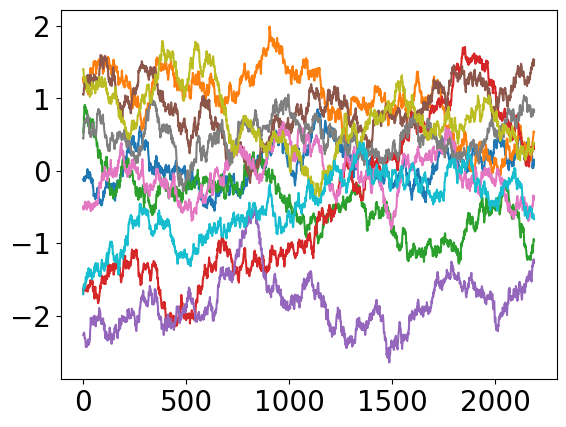

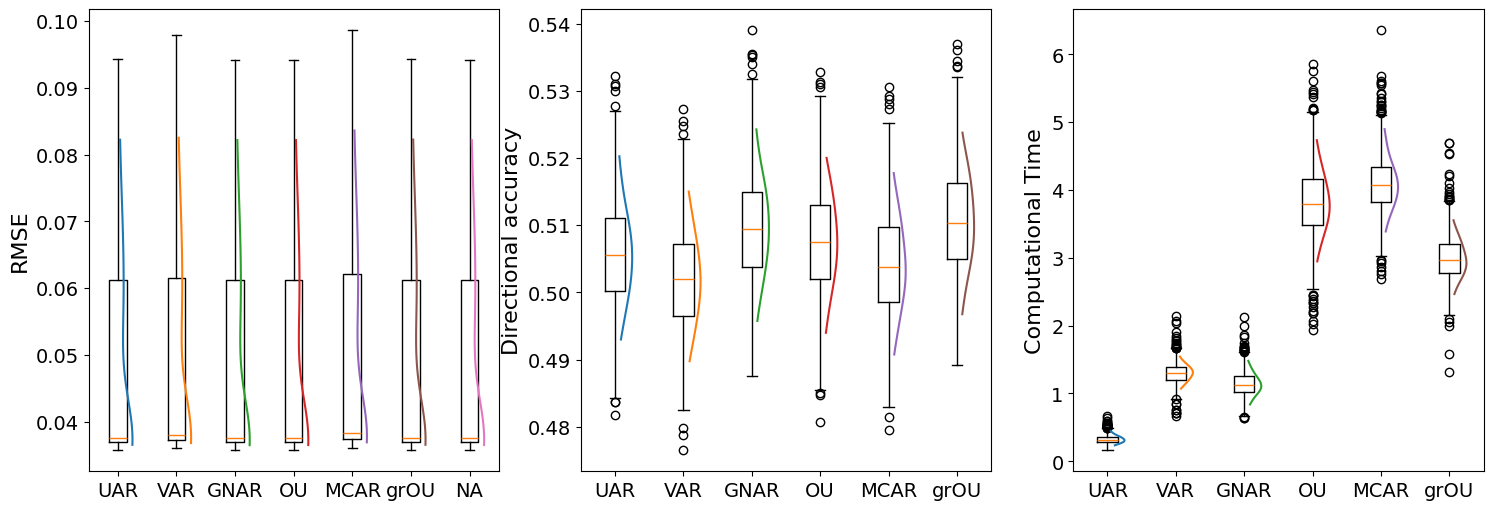

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049833  0.050137  0.049800  0.049815  0.050462   
RMSE_std                   0.016512  0.016499  0.016514  0.016513  0.016645   
Directional_accuracy_mean  0.505724  0.501967  0.509640  0.507395  0.504055   
Directional_accuracy_std   0.008113  0.007812  0.008412  0.008215  0.008271   
Computational_time_mean    0.328300  1.302185  1.144029  3.816535  4.097527   
Computational_time_std     0.066800  0.156232  0.195177  0.543190  0.453378   

                               grOU        NA  
RMSE_mean                  0.049866  0.049804  
RMSE_std                   0.016505  0.016513  
Directional_accuracy_mean  0.510528       NaN  
Directional_accuracy_std   0.008157       NaN  
Computational_time_mean    2.995075       NaN  
Computational_time_std     0.349065       NaN  


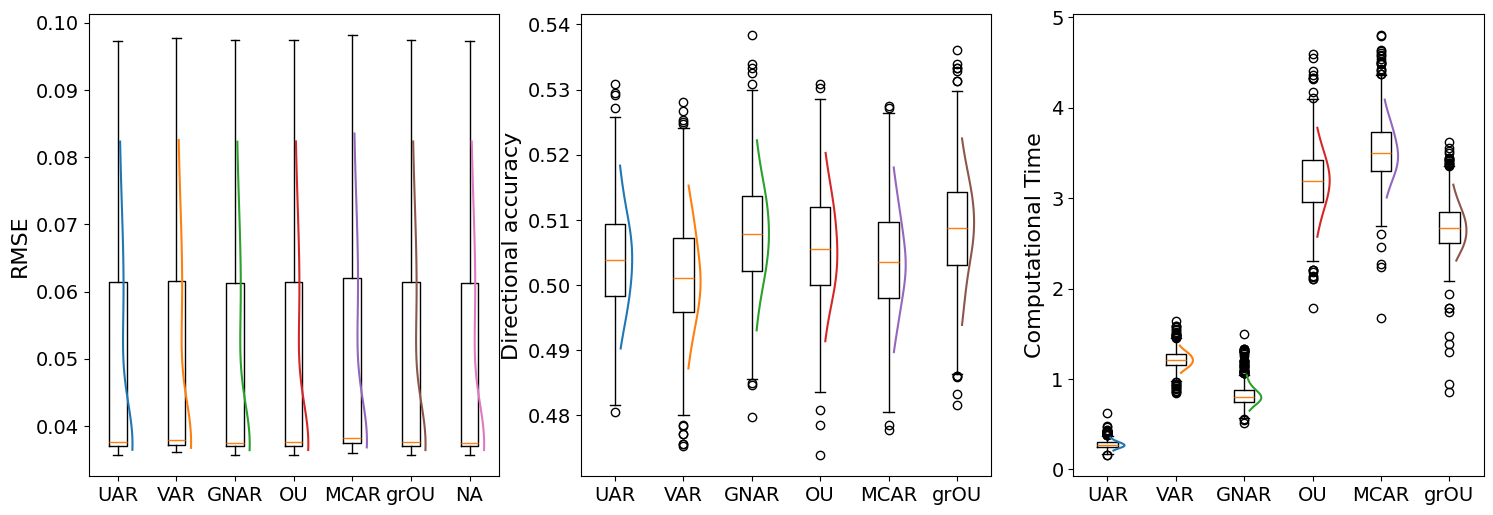

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049820  0.050088  0.049787  0.049831  0.050373   
RMSE_std                   0.016649  0.016635  0.016651  0.016679  0.016780   
Directional_accuracy_mean  0.503990  0.501297  0.507898  0.505878  0.503678   
Directional_accuracy_std   0.008435  0.008523  0.008615  0.008681  0.008561   
Computational_time_mean    0.275100  1.213539  0.822689  3.187566  3.521566   
Computational_time_std     0.045911  0.099584  0.124599  0.371718  0.345426   

                               grOU        NA  
RMSE_mean                  0.049809  0.049783  
RMSE_std                   0.016645  0.016648  
Directional_accuracy_mean  0.508571       NaN  
Directional_accuracy_std   0.008653       NaN  
Computational_time_mean    2.684526       NaN  
Computational_time_std     0.281621       NaN  


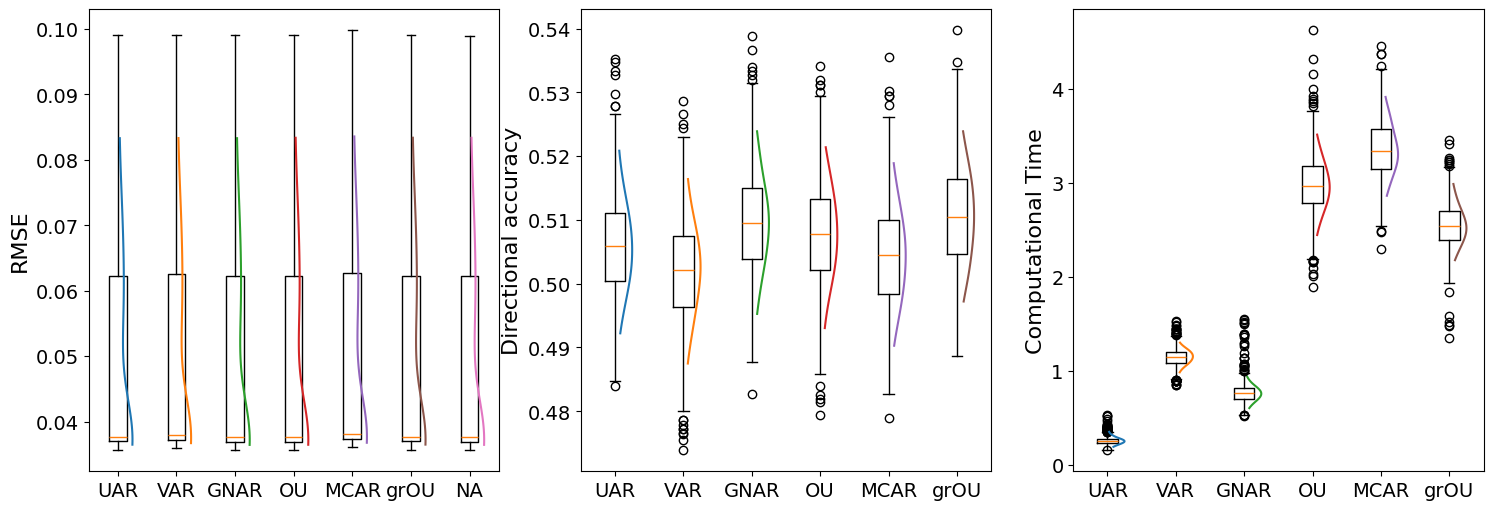

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049939  0.050205  0.049908  0.049925  0.050443   
RMSE_std                   0.016595  0.016584  0.016598  0.016594  0.016696   
Directional_accuracy_mean  0.505941  0.501984  0.509549  0.507621  0.504385   
Directional_accuracy_std   0.008484  0.008523  0.008598  0.008533  0.008619   
Computational_time_mean    0.257933  1.146982  0.767245  2.981959  3.367255   
Computational_time_std     0.047990  0.097110  0.119776  0.327110  0.320402   

                               grOU        NA  
RMSE_mean                  0.049966  0.049911  
RMSE_std                   0.016588  0.016597  
Directional_accuracy_mean  0.510488       NaN  
Directional_accuracy_std   0.008340       NaN  
Computational_time_mean    2.554413       NaN  
Computational_time_std     0.251393       NaN  


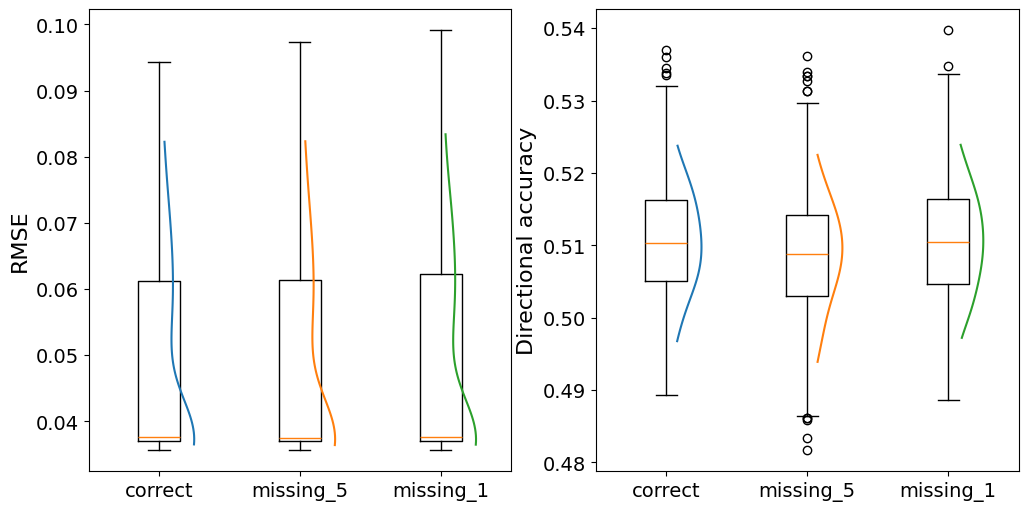

In [22]:
# Scale = 1, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_1_beta_2_rate_1', scale=1, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)
# Uncomment this part for verification

# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_1_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_1_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_1_beta_2_rate_1')

boxplot_(data_sim, 'scale_1_beta_2_rate_1')

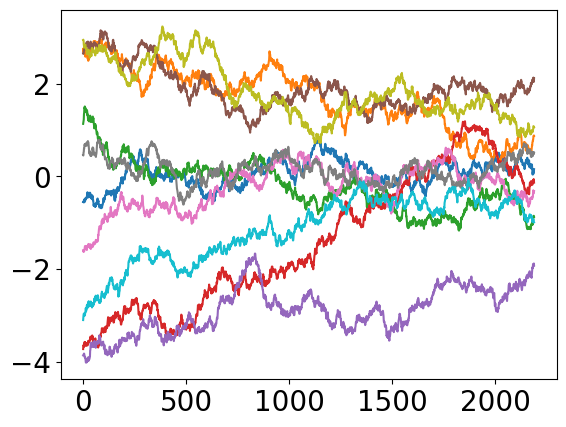

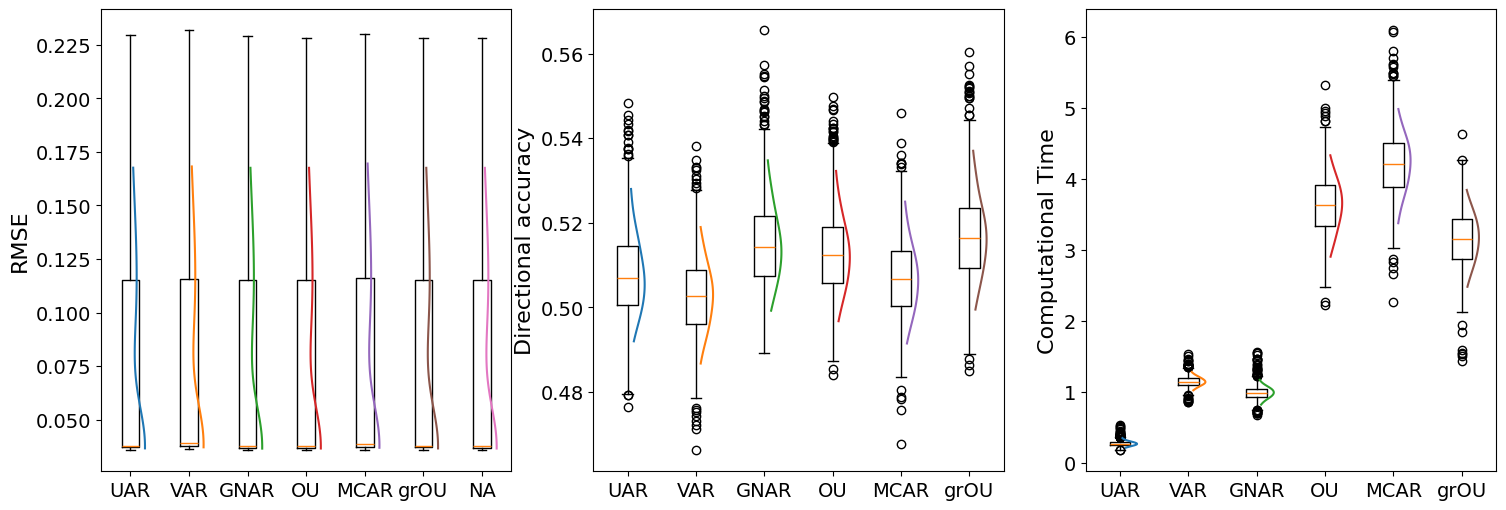

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.076693  0.077482  0.076611  0.076624  0.077537   
RMSE_std                   0.049143  0.048994  0.049159  0.049145  0.049495   
Directional_accuracy_mean  0.507958  0.502773  0.515208  0.512911  0.506918   
Directional_accuracy_std   0.010798  0.009872  0.010997  0.010552  0.009933   
Computational_time_mean    0.276935  1.148586  0.995034  3.632447  4.208465   
Computational_time_std     0.042671  0.081637  0.111228  0.437485  0.488270   

                               grOU        NA  
RMSE_mean                  0.076682  0.076616  
RMSE_std                   0.049130  0.049153  
Directional_accuracy_mean  0.516993       NaN  
Directional_accuracy_std   0.011409       NaN  
Computational_time_mean    3.157189       NaN  
Computational_time_std     0.424228       NaN  


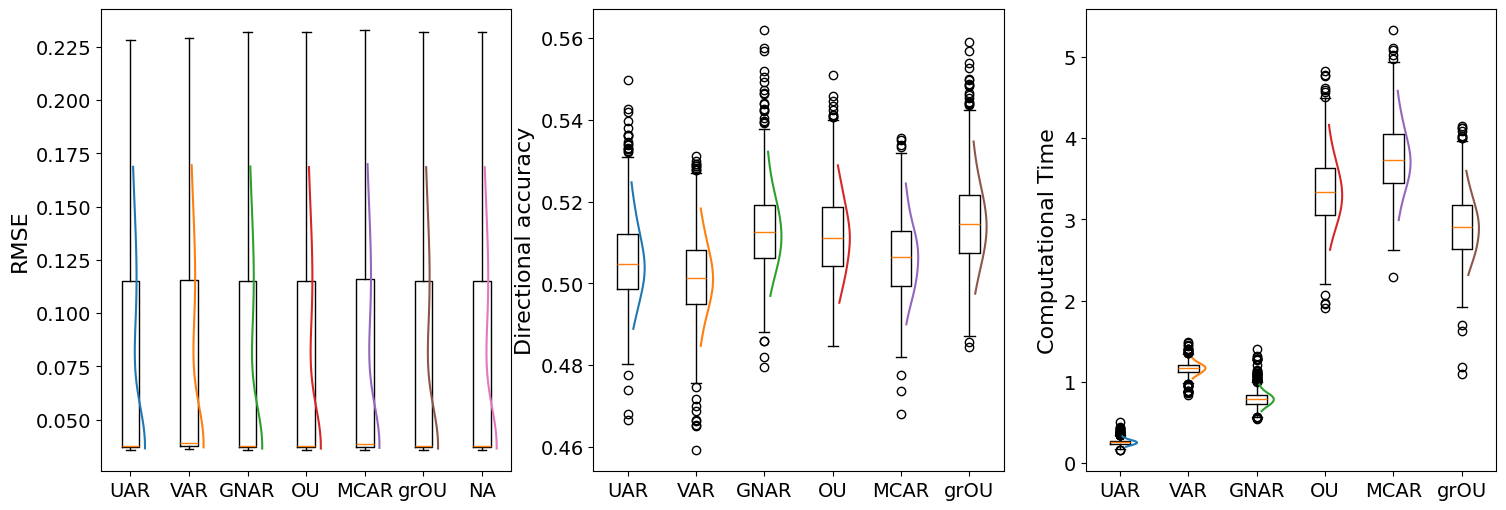

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.076613  0.077295  0.076529  0.076538  0.077321   
RMSE_std                   0.049422  0.049298  0.049438  0.049421  0.049717   
Directional_accuracy_mean  0.505523  0.501459  0.513108  0.511664  0.506531   
Directional_accuracy_std   0.010800  0.010352  0.010825  0.010496  0.010228   
Computational_time_mean    0.259421  1.165557  0.794539  3.350234  3.756197   
Computational_time_std     0.040627  0.080684  0.105915  0.445407  0.464658   

                               grOU        NA  
RMSE_mean                  0.076530  0.076520  
RMSE_std                   0.049424  0.049427  
Directional_accuracy_mean  0.515211       NaN  
Directional_accuracy_std   0.011245       NaN  
Computational_time_mean    2.915133       NaN  
Computational_time_std     0.397746       NaN  


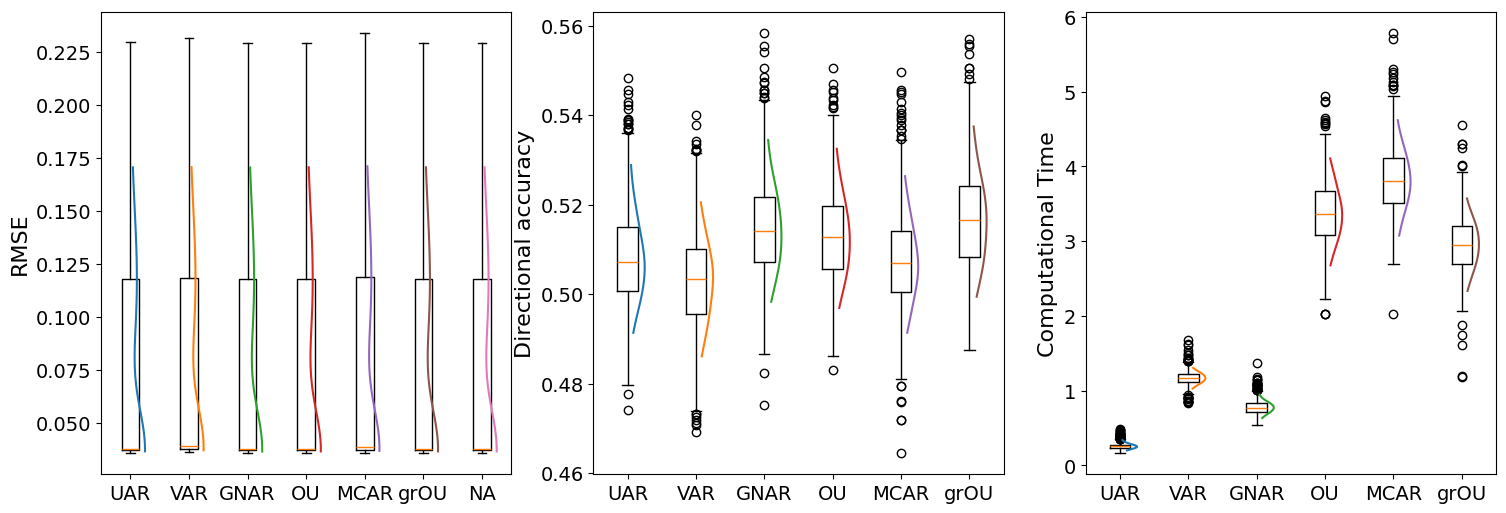

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.077018  0.077691  0.076941  0.076947  0.077688   
RMSE_std                   0.049378  0.049252  0.049395  0.049378  0.049650   
Directional_accuracy_mean  0.508240  0.503005  0.514700  0.513161  0.507598   
Directional_accuracy_std   0.011201  0.010867  0.011160  0.010752  0.010928   
Computational_time_mean    0.260597  1.170167  0.779923  3.382713  3.825777   
Computational_time_std     0.043893  0.092590  0.097569  0.436147  0.468688   

                               grOU        NA  
RMSE_mean                  0.076995  0.076942  
RMSE_std                   0.049362  0.049389  
Directional_accuracy_mean  0.516984       NaN  
Directional_accuracy_std   0.011512       NaN  
Computational_time_mean    2.951054       NaN  
Computational_time_std     0.386919       NaN  


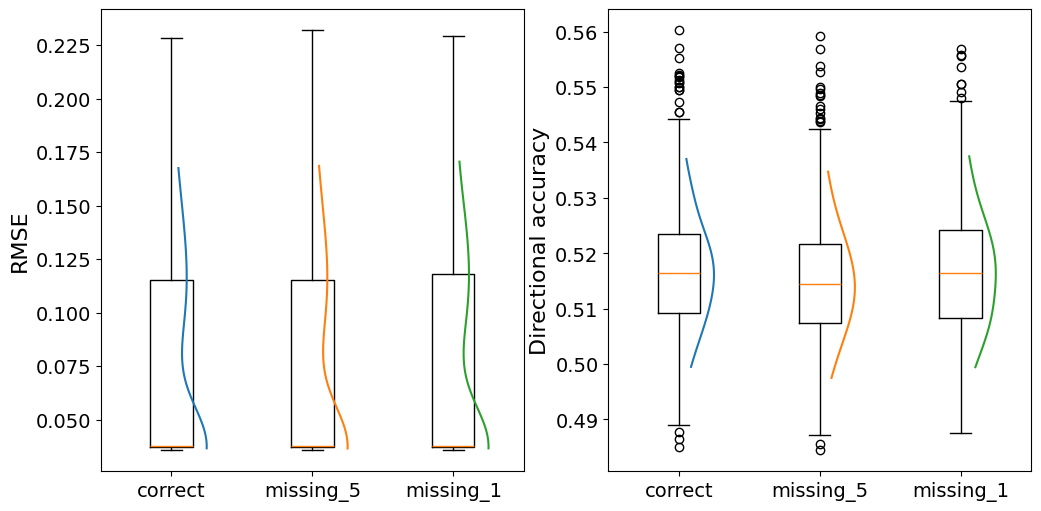

In [23]:
# Scale = 5, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_5_beta_2_rate_1', scale=5, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)
# Uncomment this part for verification

# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_5_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_5_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_5_beta_2_rate_1')

boxplot_(data_sim, 'scale_5_beta_2_rate_1')

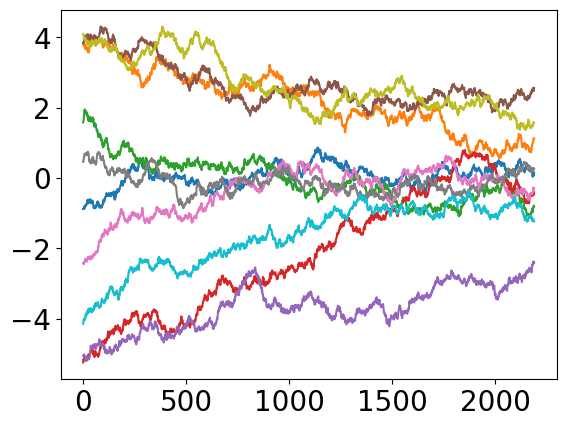

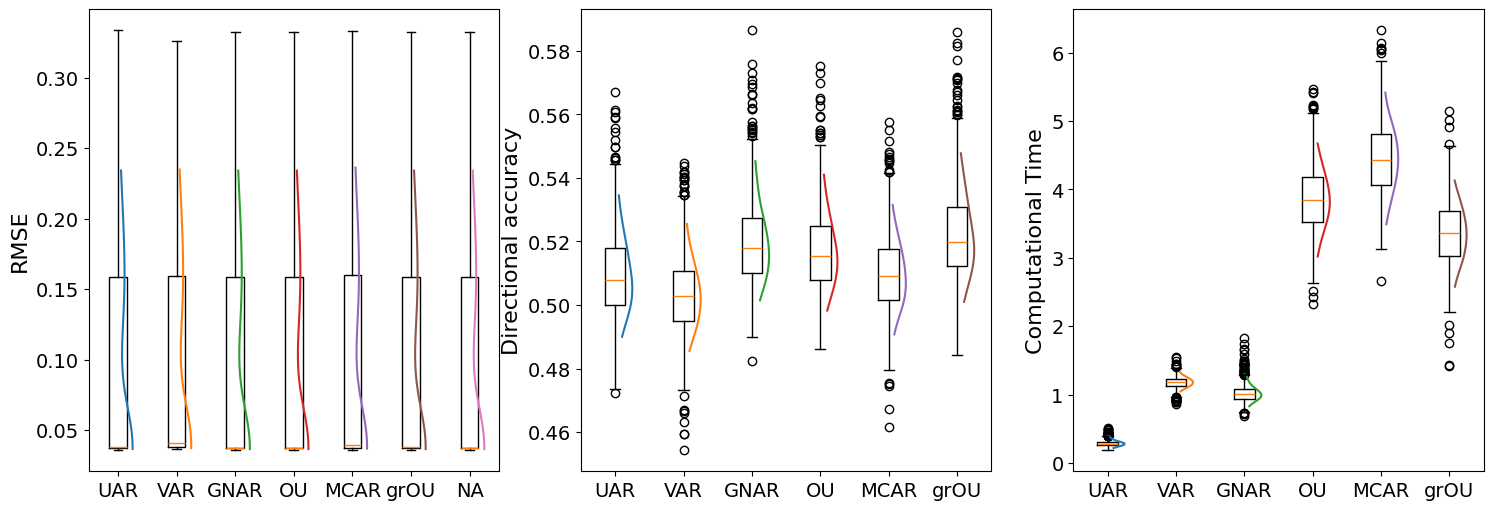

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.098108  0.099480  0.097968  0.097994  0.099157   
RMSE_std                   0.074824  0.074495  0.074864  0.074852  0.075377   
Directional_accuracy_mean  0.509559  0.503391  0.519970  0.517285  0.509834   
Directional_accuracy_std   0.013913  0.012340  0.013744  0.013245  0.012461   
Computational_time_mean    0.288018  1.180614  1.021143  3.846513  4.438482   
Computational_time_std     0.048190  0.087655  0.133523  0.497196  0.555032   

                               grOU        NA  
RMSE_mean                  0.098045  0.097975  
RMSE_std                   0.074805  0.074851  
Directional_accuracy_mean  0.522119       NaN  
Directional_accuracy_std   0.014836       NaN  
Computational_time_mean    3.349956       NaN  
Computational_time_std     0.480883       NaN  


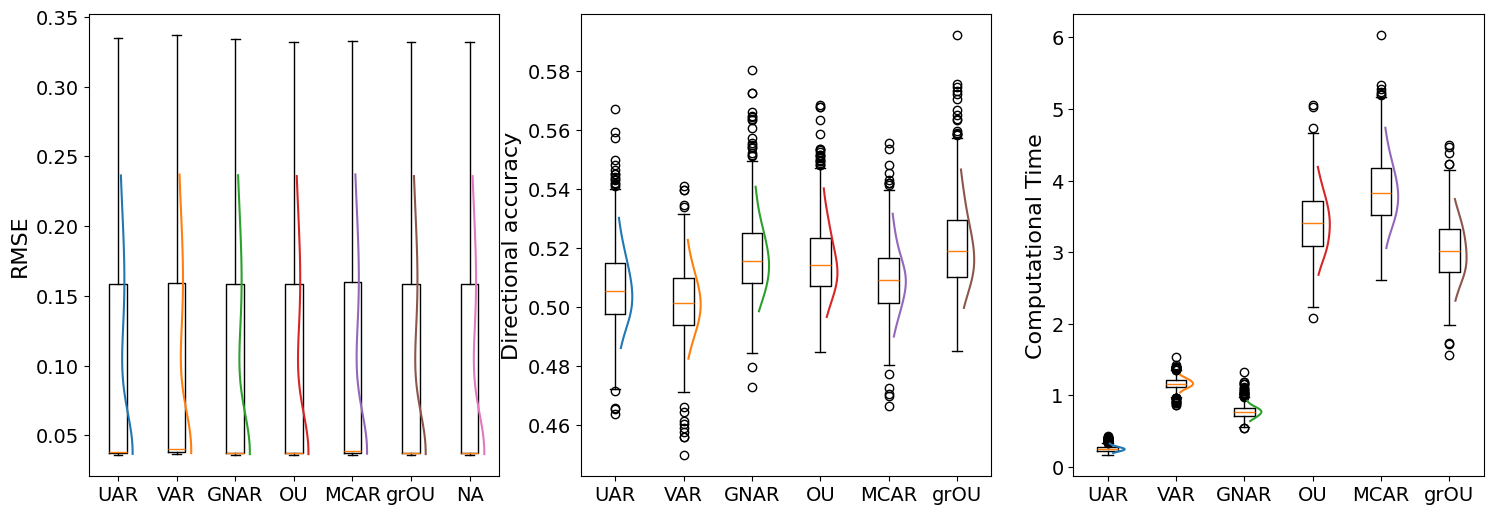

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.097978  0.099165  0.097836  0.097854  0.098839   
RMSE_std                   0.075195  0.074910  0.075234  0.075216  0.075659   
Directional_accuracy_mean  0.506584  0.501834  0.517305  0.515896  0.509663   
Directional_accuracy_std   0.013546  0.012305  0.013299  0.013021  0.012331   
Computational_time_mean    0.255403  1.166008  0.773303  3.414966  3.859655   
Computational_time_std     0.040532  0.078042  0.090088  0.456692  0.491409   

                               grOU        NA  
RMSE_mean                  0.097835  0.097821  
RMSE_std                   0.075202  0.075216  
Directional_accuracy_mean  0.520717       NaN  
Directional_accuracy_std   0.014490       NaN  
Computational_time_mean    3.020852       NaN  
Computational_time_std     0.429500       NaN  


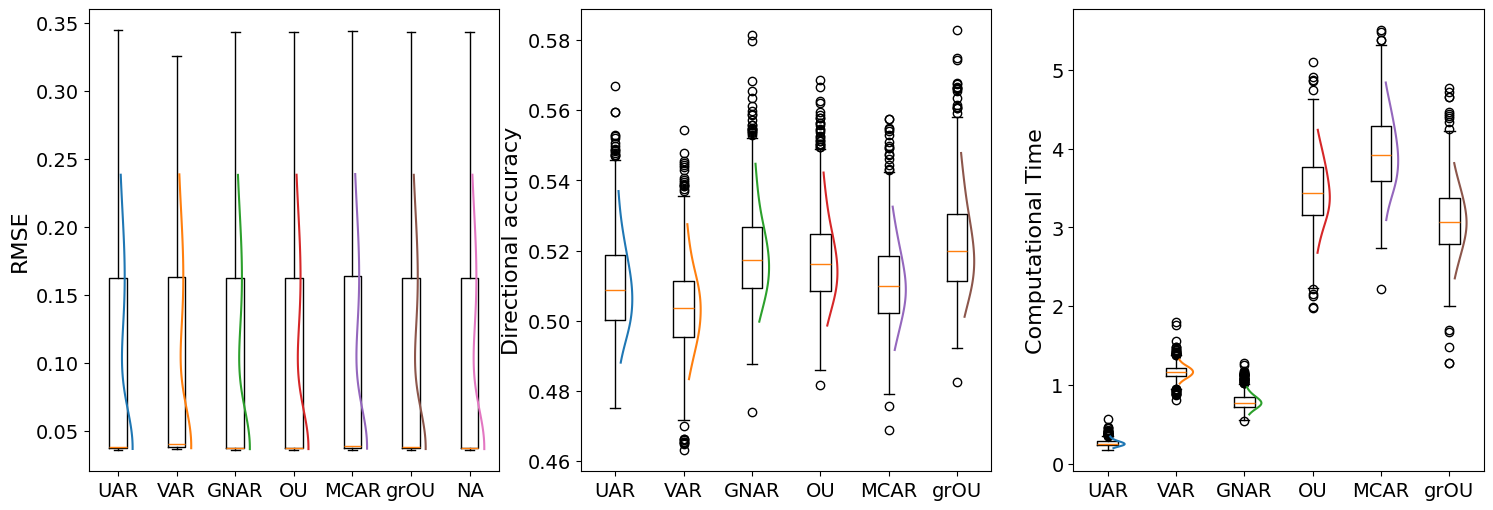

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.098523  0.099684  0.098391  0.098390  0.099336   
RMSE_std                   0.075160  0.074869  0.075199  0.075182  0.075580   
Directional_accuracy_mean  0.509897  0.503996  0.519103  0.517531  0.510729   
Directional_accuracy_std   0.014266  0.013325  0.013862  0.013200  0.012709   
Computational_time_mean    0.260988  1.168161  0.787207  3.453068  3.949352   
Computational_time_std     0.044650  0.094230  0.105698  0.470422  0.512624   

                               grOU        NA  
RMSE_mean                  0.098452  0.098391  
RMSE_std                   0.075146  0.075188  
Directional_accuracy_mean  0.521895       NaN  
Directional_accuracy_std   0.014550       NaN  
Computational_time_mean    3.078896       NaN  
Computational_time_std     0.450489       NaN  


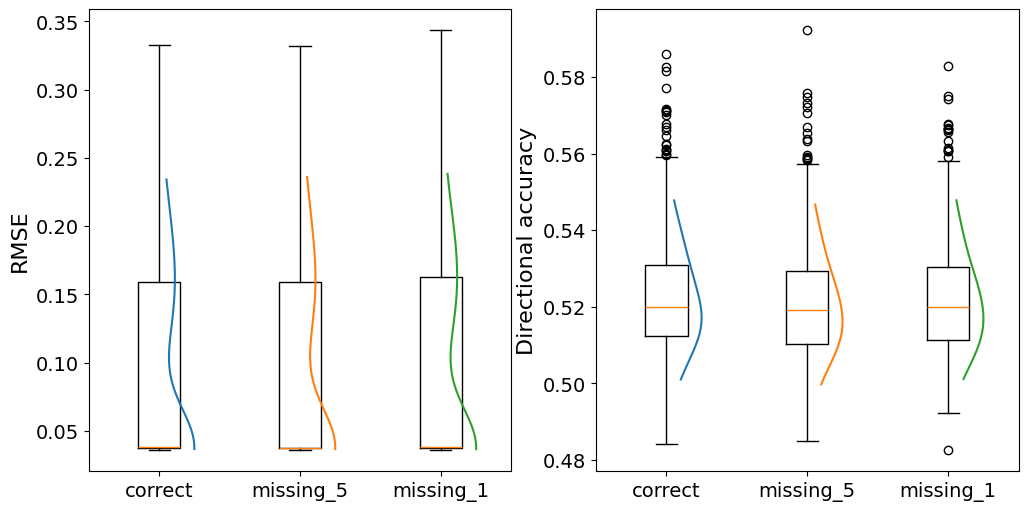

In [24]:
# Scale = 10, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_10_beta_2_rate_1', scale=10, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)
# Uncomment this part for verification

# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_10_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_10_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_10_beta_2_rate_1')

boxplot_(data_sim, 'scale_10_beta_2_rate_1')